# Method bench 3, Phase R (RGB): every arm alone, on the same tiles as Phase G

**What this is.** Phase R uses the colour bands. **R0** is the colour baseline: production's 93 road features computed
per band (R, G, B) in place of grey, same forest, folds and seeds. Every Phase R arm is compared with R0 and with
production. Plan: `outputs/preregistration_method_bench_3.md`; numbers: `evidence/pilot_scripts/method_bench_3/bench3r_numbers.json`; carry-overs from
Phase G: `evidence/pilot_scripts/method_bench_3/carry_R.json` (gates ['B1p EM-Bayes pooled', 'B1 EM-Bayes hysteresis'], corrections ['L1 Poisson seam', 'P1 Pan C tile'], decision arms ['Q1 1/t on C0 current two-date', 'PULb binned c']).

**Arms shown.**
- Gates: **D1e** IHOT on RGB pairs (two-date iterated haze index, Chen 2016) with the EM/Bayes cut, **D1e-BR** blue and
  red only, and the Phase G gates carried over in RGB form (dark channel = minimum over bands).
- Corrections: **A2b** Zhang & Guindon HOT haze correction (lower-bound slope over ΔHOT in (2, 20], two-date water proxy;
  pixels above 20 are "cannot assess"), **A2b-noW** without the water proxy, **A2b-auto** with a data-driven lower
  limit, and the Phase G corrections carried over in colour.
- Cue: **ISFA** (iterative slow feature analysis, Wu 2014) change magnitude added to R0's columns; ISFA-grey control.

RGB corrections are shown in colour and scored as their grey copy against the grey NOAA view (one yardstick for both
phases). Road colours as in notebook 01.

In [1]:
import sys, json
sys.path.insert(0, '../../evidence/pilot_scripts/method_bench_3')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 70
import nbviz as V
num = V.numbers('R')
kept = V.kept_table('R')
tiles = json.loads((V.NB / 'R_tiles.json').read_text())
print('tiles:', tiles['chosen'])

tiles: [['thin cloud', '0_13_5'], ['thick cloud', '0_11_4'], ['clear', '0_15_8'], ['flooded', '2_20_58'], ['smoke tile', '2_23_44'], ['smoke tile', '2_19_55']]


In [2]:
CORR = ['A2b HOT lower-bound', 'A2b-noW no water proxy', 'A2b-auto MAD limit', 'RGB L1 Poisson seam', 'RGB P1 Pan C tile']
GATES = ['rise', 'D1e IHOT-RGB', 'D1e-BR IHOT blue-red', 'RGB B1p EM-Bayes pooled', 'RGB B1 EM-Bayes hysteresis']
FLOOD = ['R0 colour baseline', 'D1e IHOT-RGB', 'D1e-BR IHOT blue-red', 'RGB B1p EM-Bayes pooled', 'RGB B1 EM-Bayes hysteresis', 'A2b HOT lower-bound', 'A2b-noW no water proxy', 'A2b-auto MAD limit', 'RGB L1 Poisson seam', 'RGB P1 Pan C tile', 'Q1 1/t on RGB L1 Poisson seam', 'Q1 1/t on RGB P1 Pan C tile', 'ISFA-RGB IWD + SFA1', 'ISFA-grey control', 'RGB PULb binned c']

### Thin cloud: tile `0_13_5`

This tile has the **largest thin-cloud area** of the Ida tiles: the ground is still visible through the haze. A good correction makes the hazy part look like the NOAA aerial photo (road edges and roofs with normal contrast and brightness, no grey veil, no dark blotches). In the |image − NOAA| maps, darker inside the cloud means closer to NOAA.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 946,455 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- Not an Ida prep tile, so no NOAA view and no opaque share is listed.
- Touched roads: 16; labelled flooded: 0 (source: SN8 published labels via `sn8_heldout.touched_roads`).


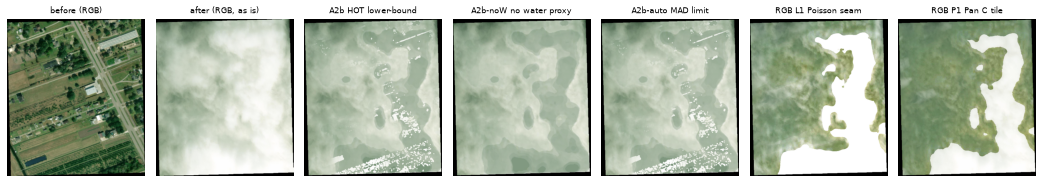

In [3]:
d = V.load('R', '0_13_5')
fig, ax = plt.subplots(1, 2 + len([c for c in CORR if 'rgb|' + c in d]), figsize=(15, 3.4))
ax[0].imshow(d['before_rgb'][::2, ::2]); ax[0].set_title('before (RGB)', fontsize=8)
ax[1].imshow(d['after_rgb'][::2, ::2]); ax[1].set_title('after (RGB, as is)', fontsize=8)
k = 2
for c in CORR:
    if 'rgb|' + c in d:
        ax[k].imshow(d['rgb|' + c][::2, ::2]); ax[k].set_title(c[:28], fontsize=8); k += 1
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Gate masks** (red = flagged), the iHOT haze index (bright = hazy) and the ISFA change magnitude (bright = changed).

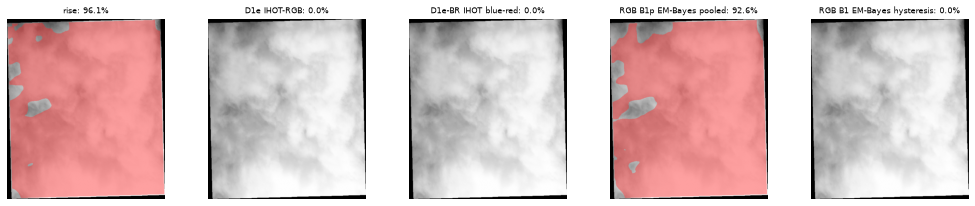

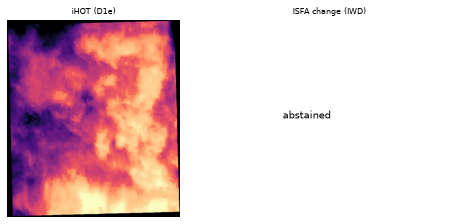

In [4]:
V.panel_masks(d, GATES)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3))
for a, k, t in zip(ax, ['ihot', 'isfa_iwd'], ['iHOT (D1e)', 'ISFA change (IWD)']):
    (a.imshow(d[k][::2, ::2], cmap='magma') if k in d else a.text(0.3, 0.5, 'abstained'))
    a.set_title(t, fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

**Against the NOAA aerial view** (grey copies).

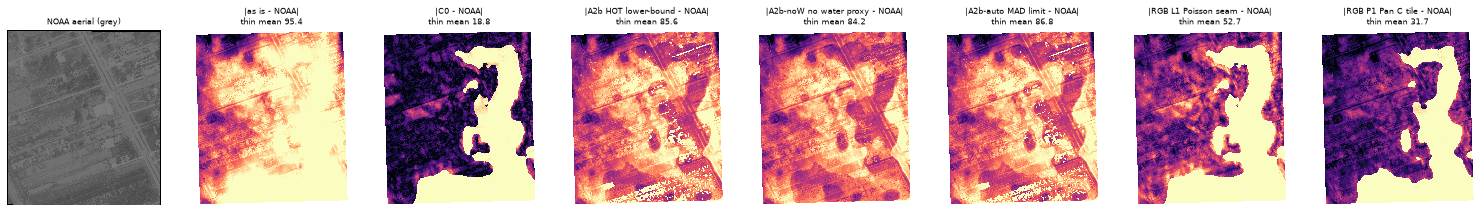

In [5]:
V.panel_noaa(d, CORR)

**Flood calls** (seed 662): production, R0 and the Phase R arms.

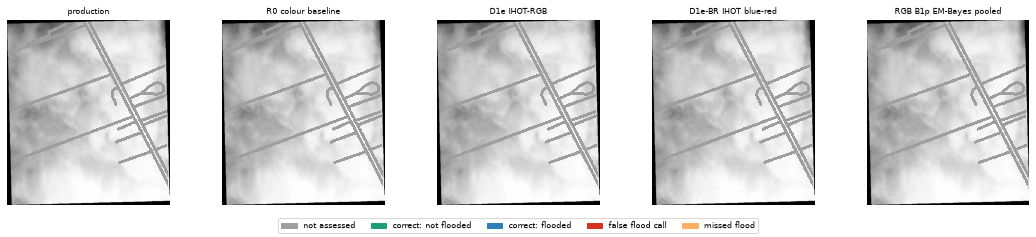

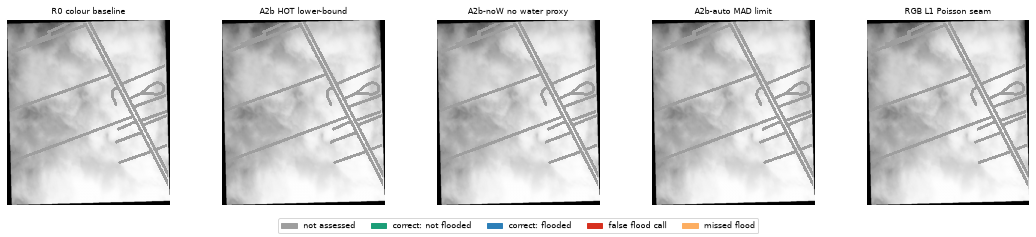

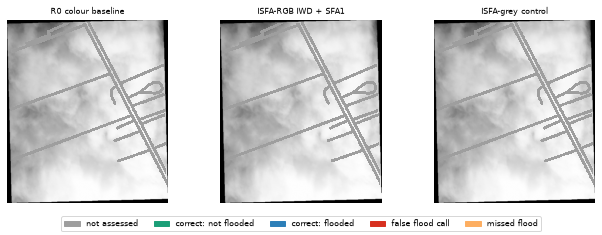

In [6]:
V.panel_calls(d, ['production', 'R0 colour baseline'] + [g for g in GATES[1:] if g in FLOOD][:3], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline'] + [c for c in CORR if c in FLOOD][:4], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline', 'ISFA-RGB IWD + SFA1', 'ISFA-grey control'], kept, phase='R')

### Thick cloud: tile `0_11_4`

This tile has the **largest opaque share** (t < 0.2). Nothing can be recovered under opaque cloud: a correction should leave it as it is, and a gate should flag it. Look for arms that paint dark patches into the cloud, and for gates that miss the core.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 351,077 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 9.7% (source: `BIG/tiles/0_11_4.pkl`, `c0_diag`).
- Touched roads: 3; labelled flooded: 0 (source: SN8 published labels via `sn8_heldout.touched_roads`).


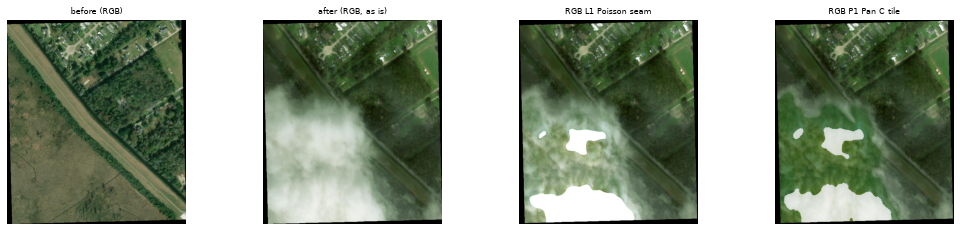

In [7]:
d = V.load('R', '0_11_4')
fig, ax = plt.subplots(1, 2 + len([c for c in CORR if 'rgb|' + c in d]), figsize=(15, 3.4))
ax[0].imshow(d['before_rgb'][::2, ::2]); ax[0].set_title('before (RGB)', fontsize=8)
ax[1].imshow(d['after_rgb'][::2, ::2]); ax[1].set_title('after (RGB, as is)', fontsize=8)
k = 2
for c in CORR:
    if 'rgb|' + c in d:
        ax[k].imshow(d['rgb|' + c][::2, ::2]); ax[k].set_title(c[:28], fontsize=8); k += 1
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Gate masks** (red = flagged), the iHOT haze index (bright = hazy) and the ISFA change magnitude (bright = changed).

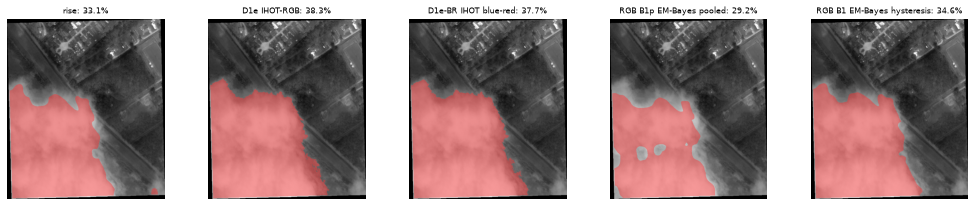

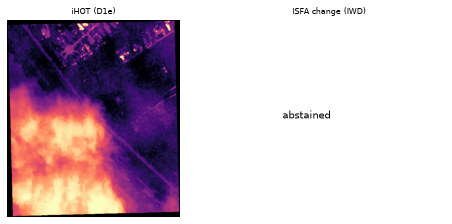

In [8]:
V.panel_masks(d, GATES)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3))
for a, k, t in zip(ax, ['ihot', 'isfa_iwd'], ['iHOT (D1e)', 'ISFA change (IWD)']):
    (a.imshow(d[k][::2, ::2], cmap='magma') if k in d else a.text(0.3, 0.5, 'abstained'))
    a.set_title(t, fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

**Against the NOAA aerial view** (grey copies).

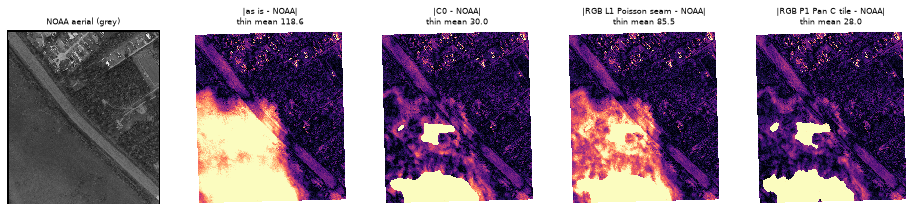

In [9]:
V.panel_noaa(d, CORR)

**Flood calls** (seed 662): production, R0 and the Phase R arms.

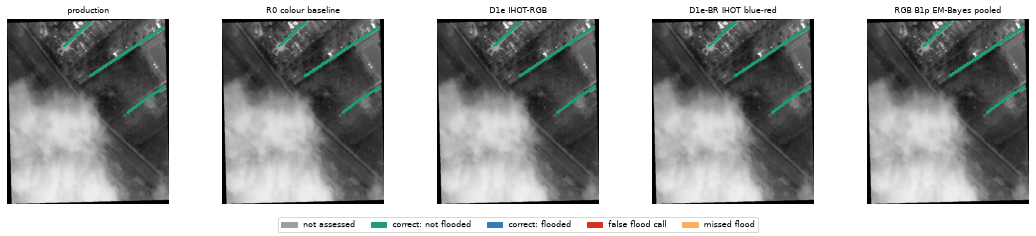

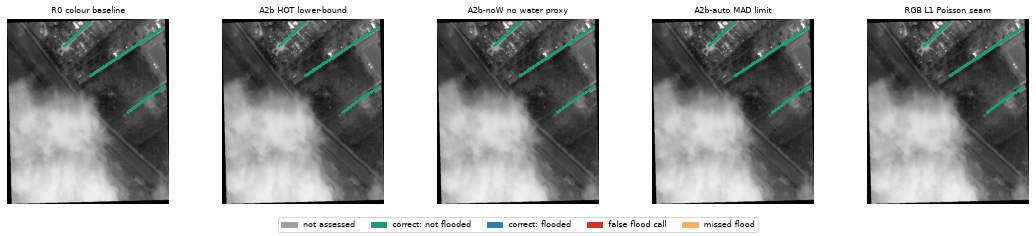

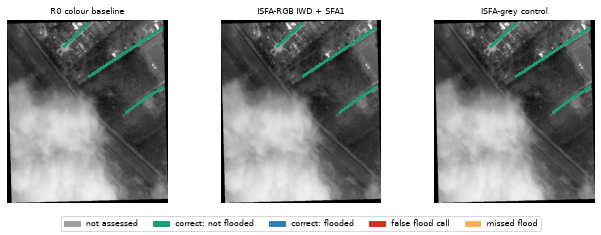

In [10]:
V.panel_calls(d, ['production', 'R0 colour baseline'] + [g for g in GATES[1:] if g in FLOOD][:3], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline'] + [c for c in CORR if c in FLOOD][:4], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline', 'ISFA-RGB IWD + SFA1', 'ISFA-grey control'], kept, phase='R')

### Clear: tile `0_15_8`

This is a **clear tile** (under 1% dark-rise and bright pixels). Every gate should flag (almost) nothing and every correction should leave the image unchanged. Any red in the gate panels is a false alarm.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 0 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 0.0% (source: `BIG/tiles/0_15_8.pkl`, `c0_diag`).
- Touched roads: 20; labelled flooded: 0 (source: SN8 published labels via `sn8_heldout.touched_roads`).


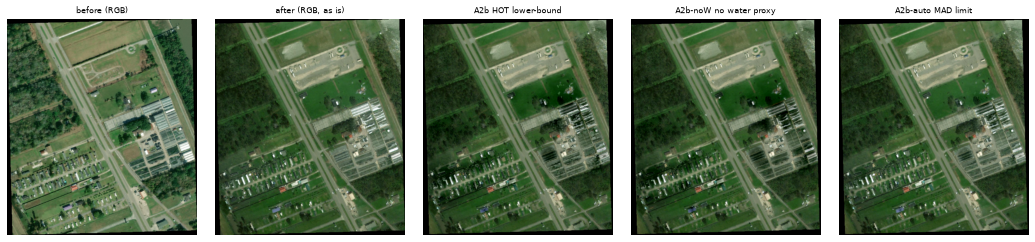

In [11]:
d = V.load('R', '0_15_8')
fig, ax = plt.subplots(1, 2 + len([c for c in CORR if 'rgb|' + c in d]), figsize=(15, 3.4))
ax[0].imshow(d['before_rgb'][::2, ::2]); ax[0].set_title('before (RGB)', fontsize=8)
ax[1].imshow(d['after_rgb'][::2, ::2]); ax[1].set_title('after (RGB, as is)', fontsize=8)
k = 2
for c in CORR:
    if 'rgb|' + c in d:
        ax[k].imshow(d['rgb|' + c][::2, ::2]); ax[k].set_title(c[:28], fontsize=8); k += 1
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Gate masks** (red = flagged), the iHOT haze index (bright = hazy) and the ISFA change magnitude (bright = changed).

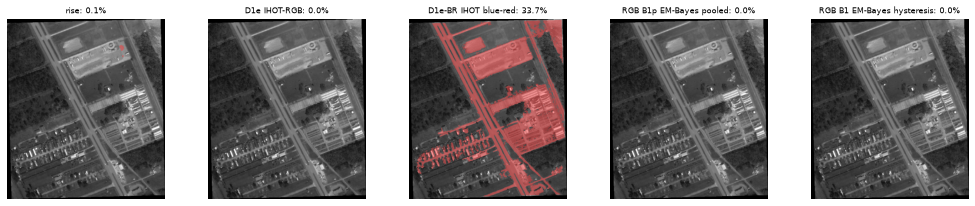

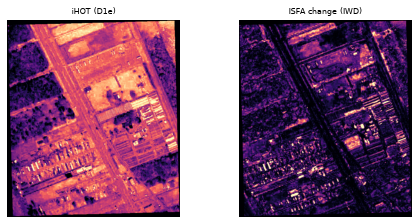

In [12]:
V.panel_masks(d, GATES)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3))
for a, k, t in zip(ax, ['ihot', 'isfa_iwd'], ['iHOT (D1e)', 'ISFA change (IWD)']):
    (a.imshow(d[k][::2, ::2], cmap='magma') if k in d else a.text(0.3, 0.5, 'abstained'))
    a.set_title(t, fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

**Against the NOAA aerial view** (grey copies).

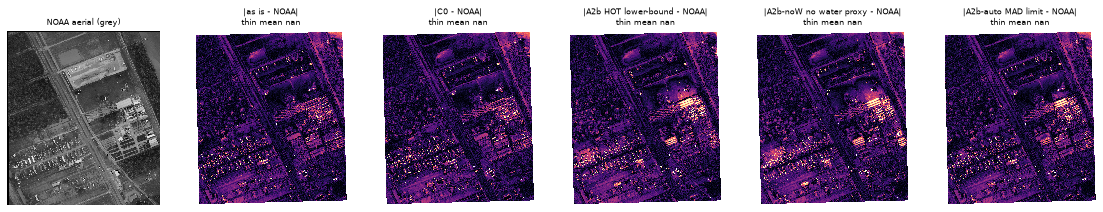

In [13]:
V.panel_noaa(d, CORR)

**Flood calls** (seed 662): production, R0 and the Phase R arms.

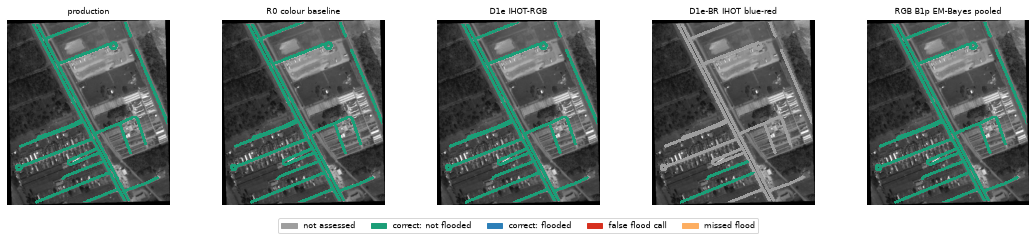

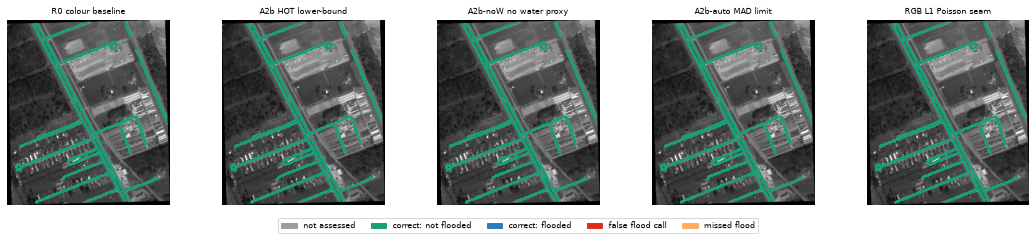

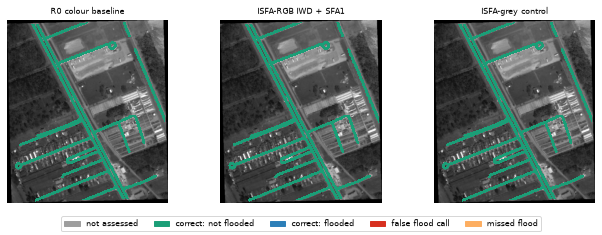

In [14]:
V.panel_calls(d, ['production', 'R0 colour baseline'] + [g for g in GATES[1:] if g in FLOOD][:3], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline'] + [c for c in CORR if c in FLOOD][:4], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline', 'ISFA-RGB IWD + SFA1', 'ISFA-grey control'], kept, phase='R')

### Flooded: tile `2_20_58`

This tile has the **most roads labelled flooded** among the tiles with a cloud gate. Check whether the flood calls (blue = flooded and called flooded, orange = flooded but missed, red = false flood call) change between arms, and whether a gate hides flooded roads (grey = not assessed).

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 0 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- Not an Ida prep tile, so no NOAA view and no opaque share is listed.
- Touched roads: 24; labelled flooded: 24 (source: SN8 published labels via `sn8_heldout.touched_roads`).


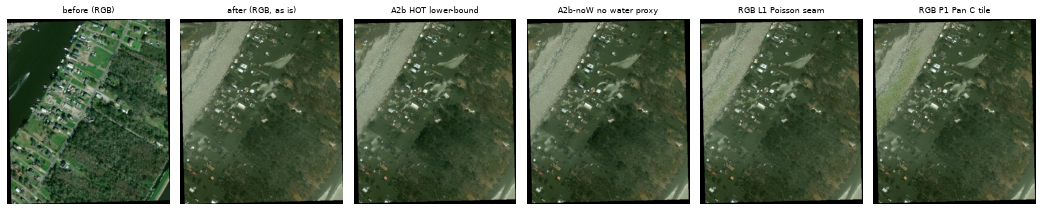

In [15]:
d = V.load('R', '2_20_58')
fig, ax = plt.subplots(1, 2 + len([c for c in CORR if 'rgb|' + c in d]), figsize=(15, 3.4))
ax[0].imshow(d['before_rgb'][::2, ::2]); ax[0].set_title('before (RGB)', fontsize=8)
ax[1].imshow(d['after_rgb'][::2, ::2]); ax[1].set_title('after (RGB, as is)', fontsize=8)
k = 2
for c in CORR:
    if 'rgb|' + c in d:
        ax[k].imshow(d['rgb|' + c][::2, ::2]); ax[k].set_title(c[:28], fontsize=8); k += 1
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Gate masks** (red = flagged), the iHOT haze index (bright = hazy) and the ISFA change magnitude (bright = changed).

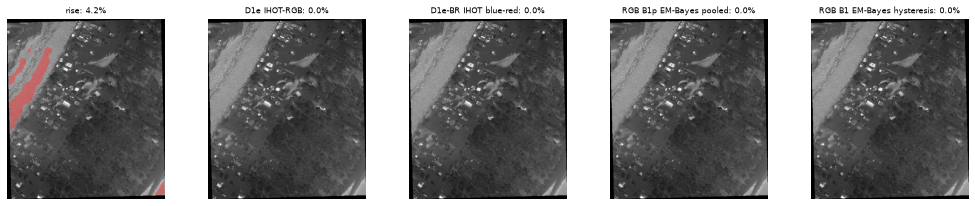

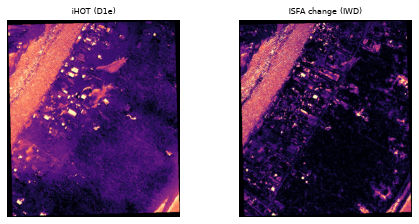

In [16]:
V.panel_masks(d, GATES)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3))
for a, k, t in zip(ax, ['ihot', 'isfa_iwd'], ['iHOT (D1e)', 'ISFA change (IWD)']):
    (a.imshow(d[k][::2, ::2], cmap='magma') if k in d else a.text(0.3, 0.5, 'abstained'))
    a.set_title(t, fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

**Against the NOAA aerial view** (grey copies).

In [17]:
V.panel_noaa(d, CORR)

No NOAA view for this tile (it is not among the Ida prep tiles).


**Flood calls** (seed 662): production, R0 and the Phase R arms.

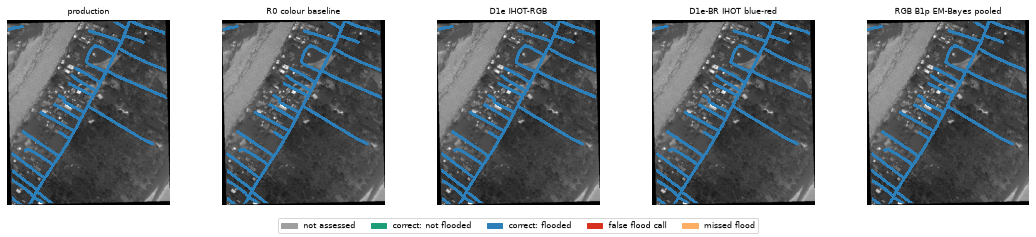

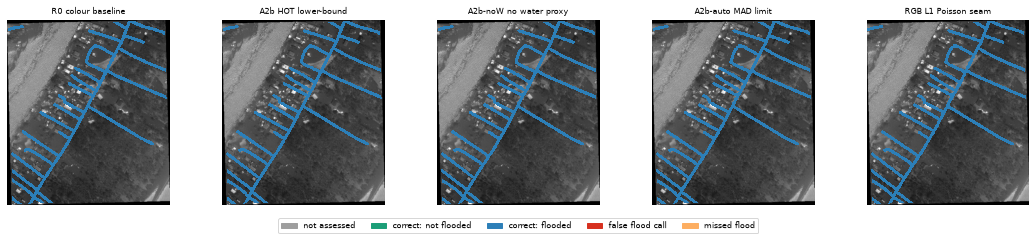

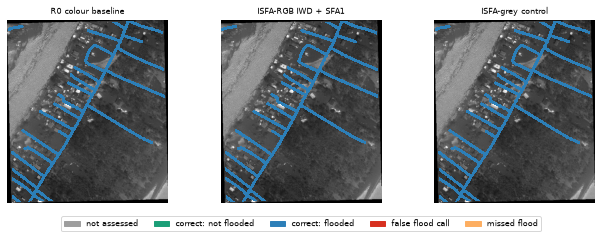

In [18]:
V.panel_calls(d, ['production', 'R0 colour baseline'] + [g for g in GATES[1:] if g in FLOOD][:3], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline'] + [c for c in CORR if c in FLOOD][:4], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline', 'ISFA-RGB IWD + SFA1', 'ISFA-grey control'], kept, phase='R')

### Smoke tile: tile `2_23_44`

One of the three **smoke-test tiles** (preregistration amendments). It is shown so the smoke notes can be checked against the images.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 451,178 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 4.5% (source: `BIG/tiles/2_23_44.pkl`, `c0_diag`).
- Touched roads: 3; labelled flooded: 2 (source: SN8 published labels via `sn8_heldout.touched_roads`).


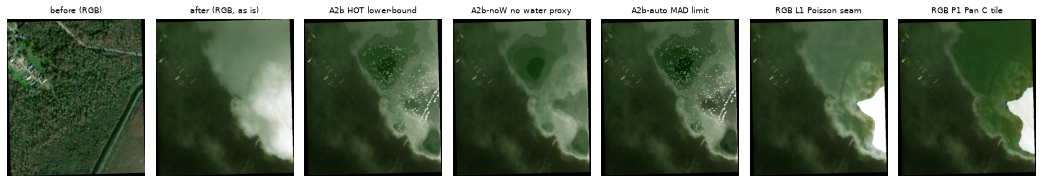

In [19]:
d = V.load('R', '2_23_44')
fig, ax = plt.subplots(1, 2 + len([c for c in CORR if 'rgb|' + c in d]), figsize=(15, 3.4))
ax[0].imshow(d['before_rgb'][::2, ::2]); ax[0].set_title('before (RGB)', fontsize=8)
ax[1].imshow(d['after_rgb'][::2, ::2]); ax[1].set_title('after (RGB, as is)', fontsize=8)
k = 2
for c in CORR:
    if 'rgb|' + c in d:
        ax[k].imshow(d['rgb|' + c][::2, ::2]); ax[k].set_title(c[:28], fontsize=8); k += 1
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Gate masks** (red = flagged), the iHOT haze index (bright = hazy) and the ISFA change magnitude (bright = changed).

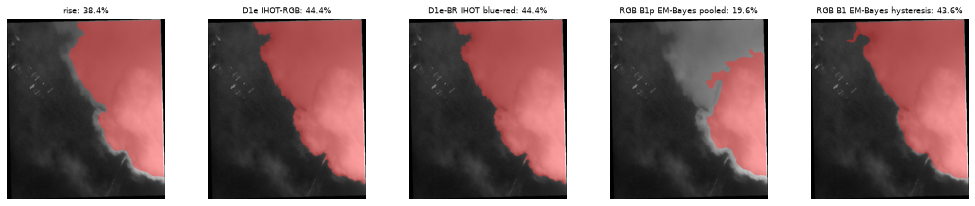

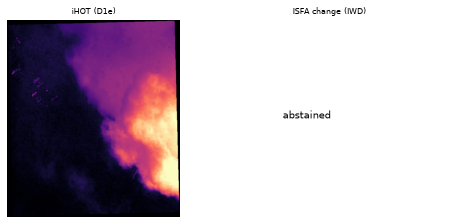

In [20]:
V.panel_masks(d, GATES)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3))
for a, k, t in zip(ax, ['ihot', 'isfa_iwd'], ['iHOT (D1e)', 'ISFA change (IWD)']):
    (a.imshow(d[k][::2, ::2], cmap='magma') if k in d else a.text(0.3, 0.5, 'abstained'))
    a.set_title(t, fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

**Against the NOAA aerial view** (grey copies).

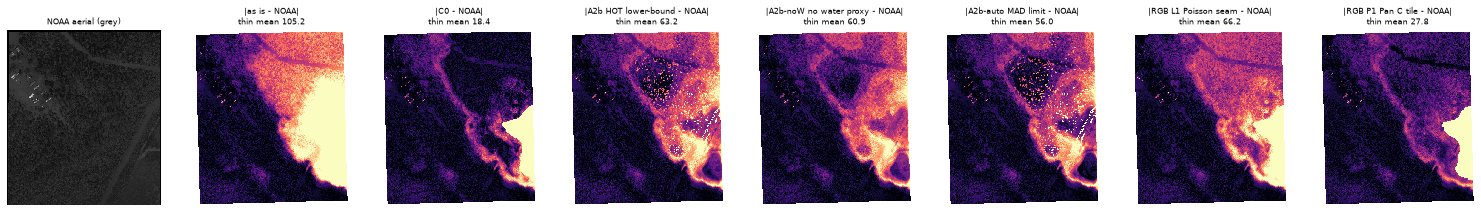

In [21]:
V.panel_noaa(d, CORR)

**Flood calls** (seed 662): production, R0 and the Phase R arms.

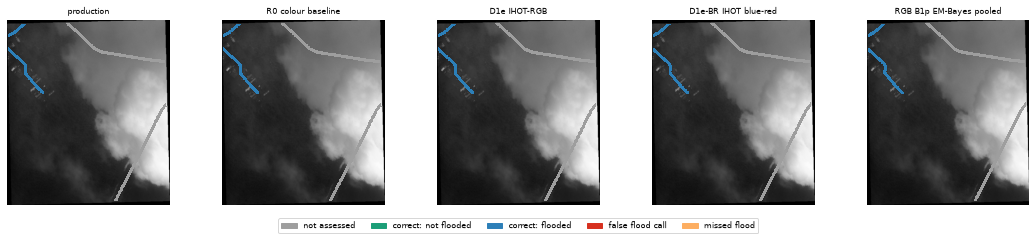

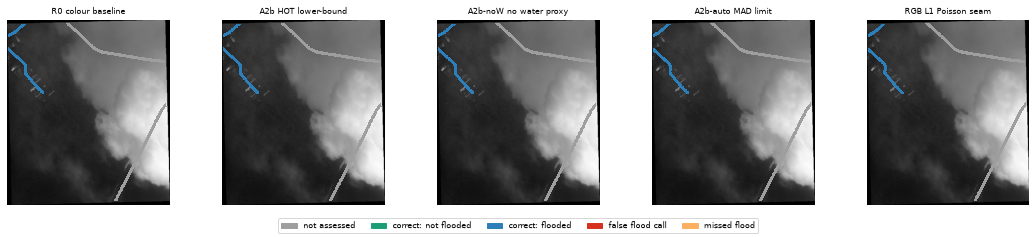

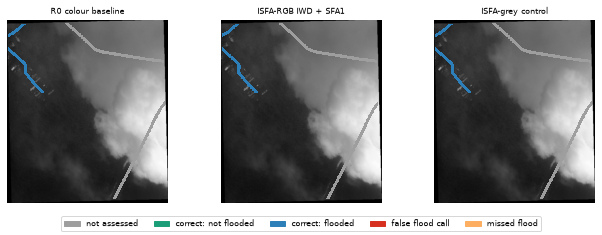

In [22]:
V.panel_calls(d, ['production', 'R0 colour baseline'] + [g for g in GATES[1:] if g in FLOOD][:3], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline'] + [c for c in CORR if c in FLOOD][:4], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline', 'ISFA-RGB IWD + SFA1', 'ISFA-grey control'], kept, phase='R')

### Smoke tile: tile `2_19_55`

One of the three **smoke-test tiles** (preregistration amendments). It is shown so the smoke notes can be checked against the images.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 213,187 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 0.3% (source: `BIG/tiles/2_19_55.pkl`, `c0_diag`).
- Touched roads: 6; labelled flooded: 6 (source: SN8 published labels via `sn8_heldout.touched_roads`).


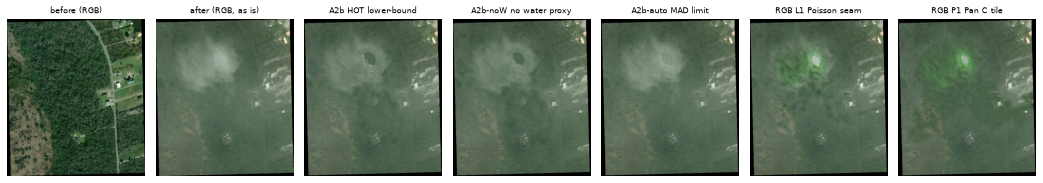

In [23]:
d = V.load('R', '2_19_55')
fig, ax = plt.subplots(1, 2 + len([c for c in CORR if 'rgb|' + c in d]), figsize=(15, 3.4))
ax[0].imshow(d['before_rgb'][::2, ::2]); ax[0].set_title('before (RGB)', fontsize=8)
ax[1].imshow(d['after_rgb'][::2, ::2]); ax[1].set_title('after (RGB, as is)', fontsize=8)
k = 2
for c in CORR:
    if 'rgb|' + c in d:
        ax[k].imshow(d['rgb|' + c][::2, ::2]); ax[k].set_title(c[:28], fontsize=8); k += 1
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Gate masks** (red = flagged), the iHOT haze index (bright = hazy) and the ISFA change magnitude (bright = changed).

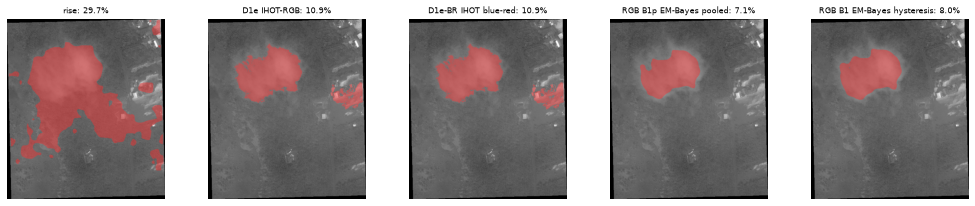

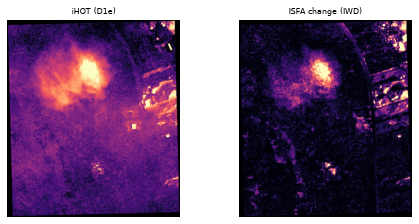

In [24]:
V.panel_masks(d, GATES)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3))
for a, k, t in zip(ax, ['ihot', 'isfa_iwd'], ['iHOT (D1e)', 'ISFA change (IWD)']):
    (a.imshow(d[k][::2, ::2], cmap='magma') if k in d else a.text(0.3, 0.5, 'abstained'))
    a.set_title(t, fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

**Against the NOAA aerial view** (grey copies).

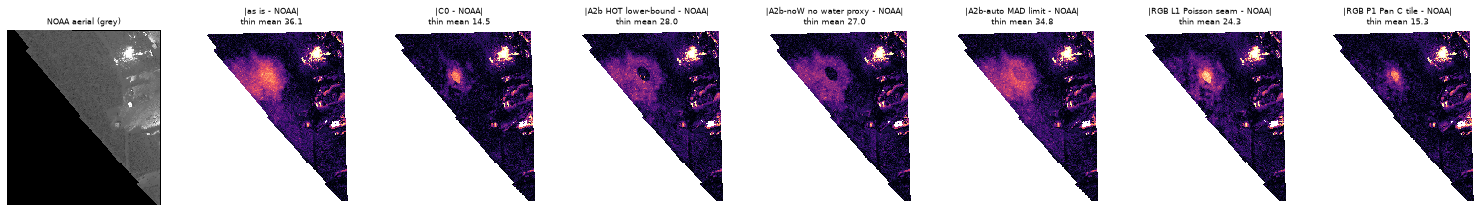

In [25]:
V.panel_noaa(d, CORR)

**Flood calls** (seed 662): production, R0 and the Phase R arms.

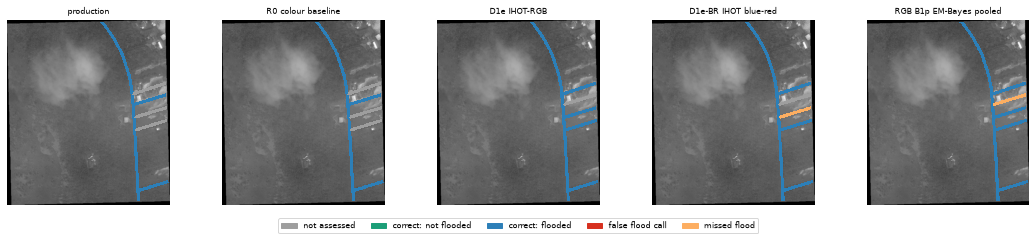

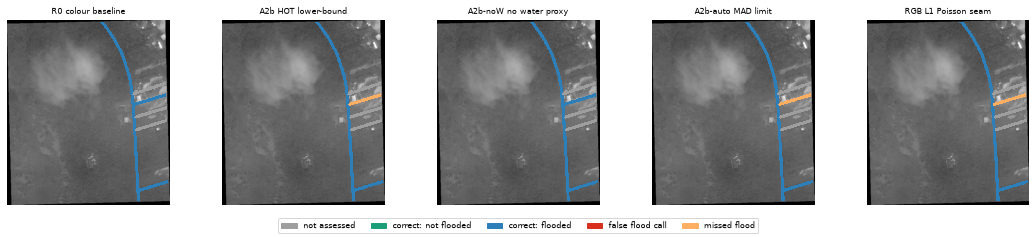

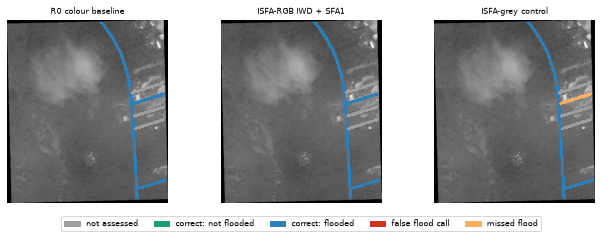

In [26]:
V.panel_calls(d, ['production', 'R0 colour baseline'] + [g for g in GATES[1:] if g in FLOOD][:3], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline'] + [c for c in CORR if c in FLOOD][:4], kept, phase='R')
V.panel_calls(d, ['R0 colour baseline', 'ISFA-RGB IWD + SFA1', 'ISFA-grey control'], kept, phase='R')

## Each Phase R arm alone (source: `evidence/pilot_scripts/method_bench_3/bench3r_numbers.json`, key `flood`; vs R0 = `vs_base`)

In [27]:
rows = []
for n, r in num['flood'].items():
    s = r['seeds']; vb = r.get('vs_base', {}).get('seeds')
    rows.append({'arm': n, 'kept': r['kept'], '21-seed gain vs production': round(100 * s['mean_gain'], 2),
                 '95% interval': f"[{100 * s['ci'][0]:+.2f}, {100 * s['ci'][1]:+.2f}]",
                 'gain vs R0': (round(100 * vb['mean_gain'], 2) if vb else None),
                 'vs R0 interval': (f"[{100 * vb['ci'][0]:+.2f}, {100 * vb['ci'][1]:+.2f}]" if vb else None)})
pd.DataFrame(rows)

,arm,kept,21-seed gain vs production,95% interval,gain vs R0,vs R0 interval
0,R0 colour baseline,798,-0.90,"[-1.76, -0.28]",NaN,NaN
1,D1e IHOT-RGB,685,-1.66,"[-3.35, +0.07]",-0.94,"[-2.34, +0.52]"
2,D1e-BR IHOT blue-red,650,-1.06,"[-2.70, +0.62]",-0.27,"[-1.62, +1.38]"
3,RGB B1p EM-Bayes pooled,854,-0.17,"[-1.06, +0.60]",0.73,"[+0.14, +1.50]"
4,RGB B1 EM-Bayes hysteresis,803,-0.18,"[-1.18, +0.61]",0.62,"[+0.12, +1.17]"
5,A2b HOT lower-bound,798,-0.72,"[-1.83, +0.27]",0.18,"[-0.47, +0.91]"
6,A2b-noW no water proxy,798,-0.98,"[-2.15, +0.08]",-0.08,"[-0.73, +0.71]"
7,A2b-auto MAD limit,798,-0.61,"[-1.90, +0.41]",0.29,"[-0.42, +0.98]"
8,RGB L1 Poisson seam,798,-0.93,"[-2.01, -0.05]",-0.03,"[-0.54, +0.57]"
9,RGB P1 Pan C tile,798,-0.19,"[-1.24, +0.69]",0.71,"[+0.10, +1.37]"


In [28]:
rows = []
for a, r in (num.get('ida_primary_vs_C0') or {}).items():
    if r:
        rows.append({'arm': a, 'tiles': r['tiles'], 'feature distance vs C0': round(r['mean_diff'], 4),
                     '95% interval': f"[{r['ci'][0]:+.4f}, {r['ci'][1]:+.4f}]", 'guard ok': r.get('guard_ok')})
pd.DataFrame(rows)

,arm,tiles,feature distance vs C0,95% interval,guard ok
0,as is,73,-0.0048,"[-0.0150, +0.0071]",False
1,A2b HOT lower-bound,46,0.0141,"[-0.0010, +0.0311]",False
2,A2b-noW no water proxy,47,0.0090,"[-0.0057, +0.0222]",False
3,A2b-auto MAD limit,35,0.0142,"[+0.0061, +0.0221]",True
4,RGB P1 Pan C tile,73,-0.0084,"[-0.0133, -0.0035]",True
5,RGB L1 Poisson seam,73,-0.0057,"[-0.0151, +0.0025]",True
